# Viviendas protegidas iniciadas al año

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "vivienda-protegida-iniciada"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Viviendas protegidas iniciadas al año"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "solo_espana"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Viviendas"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 0  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Cuántas viviendas con algún régimen de protección pública (de promoción pública o privada) empiezan a construirse cada año, según la estadística del Ministerio de Vivienda y Agenda Urbana que difunde el Banco de España.

**Cómo se lee.** Es un recuento anual de obra nueva protegida; el total de viviendas iniciadas está en la gráfica `viviendas-iniciadas`.

**Limitaciones.**
- Los regímenes de protección han cambiado con los planes de vivienda y son distintos en cada comunidad autónoma.
- Solo España: la vivienda protegida es una figura de la normativa española.

## 2. Descarga

Serie mensual `D_1KB02200` del Boletín Estadístico del Banco de España (viviendas protegidas iniciadas); el fetcher suma los doce meses de cada año completo.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import bde


def descargar():
    """Devuelve (DataFrame `serie, periodo, valor`, lista de FuenteMeta)."""
    return bde.get({'D_1KB02200': "espana"}, agregacion='suma', desde=DESDE)


df, fuentes = descargar()

## 3. Transformación

Los datos ya vienen en la unidad final: solo se pasan a años naturales en la descarga (ver notas).

In [ ]:
NOTAS = [
    'Ministerio de Vivienda y Agenda Urbana, difundido por el Banco de España: viviendas protegidas iniciadas, de promoción pública y privada.',
    'Serie mensual: se suma cada año natural; el año en curso, incompleto, no se incluye.',
    'Solo España: la vivienda protegida es una figura de la normativa española; sus regímenes cambian con los planes de vivienda y entre comunidades autónomas.',
]

## 4. Visualización

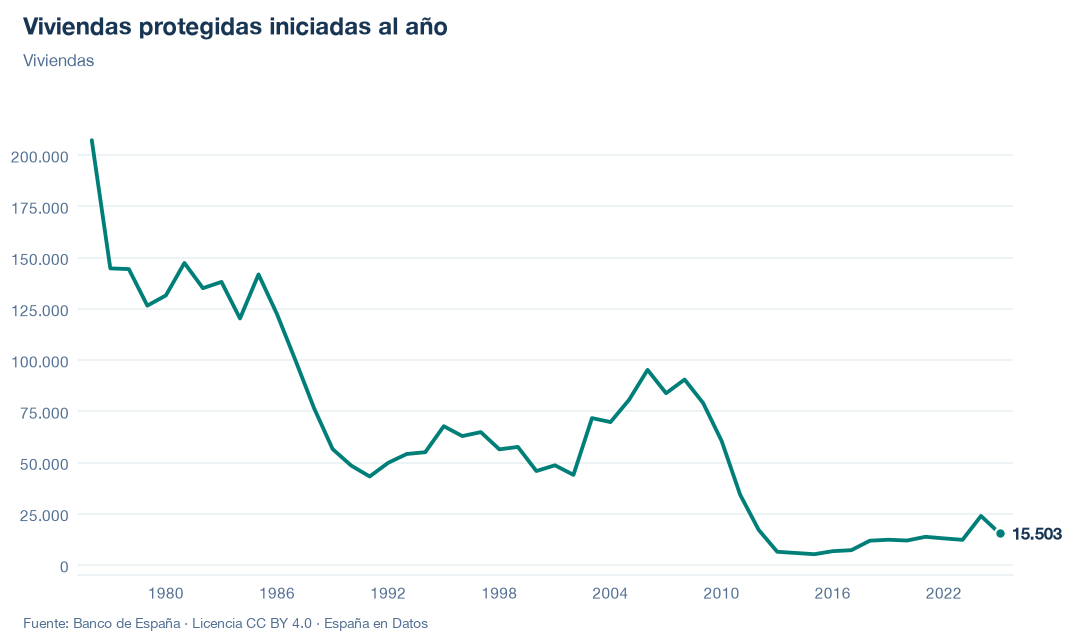

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/vivienda-protegida-iniciada.json y data/vivienda-protegida-iniciada.csv


## 6. Fuentes, notas y licencia

- Banco de España, Boletín Estadístico, serie `D_1KB02200` (datos del Ministerio de Vivienda y Agenda Urbana).

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.